[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/recsys/07-cold-start.ipynb)

# Cold Start: New Users, New Items, and Content Features

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Measure how a recommender behaves as a new user's profile grows from nothing to twenty ratings.</li>
<li>Find the point at which personalisation starts to beat popularity, and blend the two until then.</li>
<li>Quantify how much of the future a collaborative model can never recommend because the items are new.</li>
<li>Test whether content features (genres) rescue new items, and say honestly what the cost and the evidence are.</li>
</ul>
</div>

**Prerequisites:** [Matrix factorisation](05-factorisation.ipynb). **Dataset:** MovieLens small. **Time:** about 40 minutes.

## The situation

Every model so far learns from history, and every service starts every day with someone who has none: a **new user** who just signed up, a **new item** that was just added. This is the **cold-start problem**, and it is not a corner case. Growth means new users; a catalogue that changes means new items. A model that is excellent for the established users can be useless for exactly the people the business is trying to win.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from mlp_data import load_movielens, recsys as rs, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:,.4f}".format)

## Maths ↔ code

- **Fold-in** (new users): the item vectors $q_i$ of the trained implicit ALS model are held fixed, and the new user's vector $p_u$ is the closed-form solution of the same least-squares problem as in training, using just the items they have so far (`rs.fold_in`). No retraining.
- **Neighbour scoring from a profile:** the score of item $j$ is $\sum_{i \in \text{profile}} \text{sim}(i,j)$, with similarities learned from the *other* users (`rs.item_similarity`).
- **Content profile:** each movie has a multi-hot genre vector $g_j$ (`rs.genre_matrix`); a user's content profile is the mean genre vector of the movies they liked, and the score is the cosine $\cos(\bar g_u, g_j)$. It needs no other user's data.

## 1. New users: how much history is enough?

To simulate new users, take **a quarter of the users with at least 40 ratings** and remove them from training entirely. For each such user, reveal only their **first $n$ ratings** (their "profile") and score the recommendations against the **last 20 ratings** that they gave. Because they have at least 40 ratings, the profile (at most 20) and the test ratings never overlap, and the test ratings always come *after* the profile.

In [2]:
ml = load_movielens()
ratings, movies = ml.ratings, ml.movies
index = rs.make_index(ratings)
n_items = len(index.items)
item_position = pd.Series(range(n_items), index=index.items)

rng = np.random.default_rng(0)
per_user = ratings.groupby("userId").size()
eligible = per_user[per_user >= 40].index.to_numpy()
cold_users = rng.choice(eligible, size=len(eligible) // 4, replace=False)

is_cold = ratings["userId"].isin(cold_users)
warm = ratings[~is_cold]                                             # what the models are trained on
cold = ratings[is_cold].sort_values(["userId", "timestamp"], kind="stable")
print(f"{len(cold_users)} new users, {per_user[cold_users].median():.0f} ratings each (median); the models are trained on the other {warm['userId'].nunique()} users")

107 new users, 129 ratings each (median); the models are trained on the other 503 users


In [3]:
# Models trained on the warm users only; liked-only signal, as on page 5.
liked_warm = rs.to_csr(warm[warm["rating"] >= 4], index)
seen_warm = rs.to_csr(warm, index)
popularity = rs.popularity(seen_warm)
item_sim = rs.item_similarity(liked_warm, k=50, shrink=10)
als = rs.als_implicit(liked_warm, factors=32, reg=10, alpha=1, iters=10, seed=0)
genres, genre_names = rs.genre_matrix(movies, index)
genre_dense = genres.toarray()
genre_norm = np.maximum(np.linalg.norm(genre_dense, axis=1), 1e-9)

# Test ratings of each new user: the last 20 ratings; hits are the ones at 4 stars or more.
rows, cols = [], []
profiles = {}
for r, (user, g) in enumerate(cold.groupby("userId")):
    last = g.iloc[-20:]
    profiles[user] = g.iloc[:20]                                    # the first 20 ratings: n of them are revealed
    for movie in last.loc[last["rating"] >= 4, "movieId"]:
        rows.append(r); cols.append(item_position[movie])
user_ids = list(profiles)
hits = sp.csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=(len(user_ids), n_items))
print(f"{(np.asarray(hits.sum(axis=1)).ravel() > 0).sum()} of {len(user_ids)} new users have a hit among their last 20 ratings")

103 of 107 new users have a hit among their last 20 ratings


A scorer takes the new user's revealed profile and returns a score for every movie. Four of them: **popularity** (ignores the profile), **item-item** (movies similar to the liked profile movies), **ALS fold-in**, and the **content profile** from genres. Ties are broken by popularity, so a model with no information (an empty profile) falls back to the popularity list.

In [4]:
def z(v):                                                            # per-user standard score, to put two scores on one scale
    return (v - v.mean()) / max(v.std(), 1e-9)

def scorers(liked, n_liked):
    out = {"popularity": popularity.astype(np.float32)}
    if len(liked):
        out["item-item"] = np.asarray(item_sim[:, liked].sum(axis=1)).ravel()
        out["ALS fold-in"] = als.item_f @ rs.fold_in(als.item_f, np.array(liked), reg=10, alpha=1)
        profile = genre_dense[liked].mean(axis=0)
        out["genre profile"] = (genre_dense @ profile) / (np.linalg.norm(profile) * genre_norm + 1e-9)
    else:
        for name in ("item-item", "ALS fold-in", "genre profile"):
            out[name] = np.zeros(n_items, dtype=np.float32)
    weight = n_liked / (n_liked + 10)                                # personal evidence counts for more as the profile grows
    out["popularity + ALS blend"] = z(out["popularity"]) + weight * z(out["ALS fold-in"])
    return out

def evaluate_profile_size(n):
    tops = {}
    for r, user in enumerate(user_ids):
        shown = profiles[user].iloc[:n]
        liked = [item_position[m] for m in shown.loc[shown["rating"] >= 4, "movieId"]]
        for name, score in scorers(liked, len(liked)).items():
            score = np.array(score, dtype=np.float64)
            score[[item_position[m] for m in shown["movieId"]]] = -np.inf          # never recommend what was already rated
            tops.setdefault(name, []).append(np.lexsort((-popularity, -score))[:10])
    return {name: rs.rank_metrics(np.array(t), hits)["ndcg"] for name, t in tops.items()}

sizes = (0, 1, 2, 5, 10, 20)
by_size = {n: evaluate_profile_size(n) for n in sizes}
curve = pd.DataFrame({n: {name: s.mean() for name, s in res.items()} for n, res in by_size.items()}).rename_axis(columns="ratings revealed")
n_scored = len(by_size[0]["popularity"])
print(f"{n_scored} new users scored")
assert np.allclose(curve[0], curve.loc["popularity", 0])                                  # empty profile: everyone falls back to popularity
assert (curve.loc["ALS fold-in", [1, 2, 5]] < curve.loc["popularity", [1, 2, 5]]).all()     # guards the reading below
assert (curve.loc["genre profile", [1, 2, 5, 10, 20]] < curve.loc["popularity", [1, 2, 5, 10, 20]]).all()
curve

103 new users scored


ratings revealed,0,1,2,5,10,20
popularity,0.0410,0.0410,0.0411,0.0437,0.0456,0.0488
item-item,0.0410,0.0329,0.0293,0.0256,0.0332,0.0599
ALS fold-in,0.0410,0.0368,0.0370,0.0372,0.0448,0.0602
genre profile,0.0410,0.0270,0.0198,0.0088,0.0090,0.0119
popularity + ALS blend,0.0410,0.0418,0.0421,0.0480,0.0501,0.0650


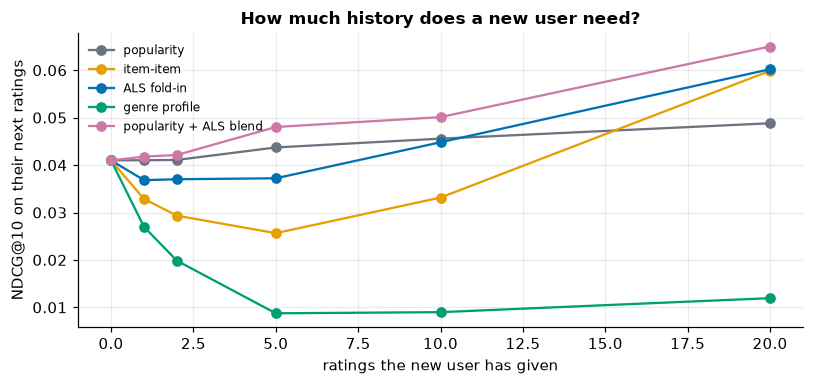

,diff,lo,hi
"20 ratings revealed, vs popularity",,,
item-item,0.0111,-0.0089,0.0310
ALS fold-in,0.0114,-0.0058,0.0286
popularity + ALS blend,0.0162,0.0050,0.0274


In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for name, color in zip(["popularity", "item-item", "ALS fold-in", "genre profile", "popularity + ALS blend"],
                       [style.GREY, style.ORANGE, style.BLUE, style.GREEN, style.PURPLE]):
    ax.plot(curve.columns, curve.loc[name], marker="o", color=color, label=name)
ax.set(xlabel="ratings the new user has given", ylabel="NDCG@10 on their next ratings", title="How much history does a new user need?")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

at20 = {name: rs.paired_difference(by_size[20][name], by_size[20]["popularity"]) for name in ("item-item", "ALS fold-in", "popularity + ALS blend")}
assert at20["popularity + ALS blend"]["lo"] > 0 > at20["ALS fold-in"]["lo"]
pd.DataFrame(at20).T[["diff", "lo", "hi"]].rename_axis("20 ratings revealed, vs popularity")

Reading the table across: with no ratings every model falls back to popularity (0.041). **Then the personal models get worse before they get better.** After one to five ratings the ALS fold-in scores 0.037 against popularity's 0.041 to 0.044, and item-item scores 0.033, 0.029 and 0.026; at ten ratings they are only level (ALS 0.0448 against 0.0456); only at **20 ratings** do item-item and ALS fold-in rise above popularity (0.060 against 0.049), and even then the gap (+0.011) has an interval that contains zero with 103 users. The **genre profile** is below popularity at every size and never recovers: knowing the genres someone likes narrows the list to a genre but not to the good movies inside it.

The **blend** (popularity plus the ALS score, the latter weighted by $n/(n+10)$ for $n$ liked profile movies, a weight fixed in advance and not tuned) is never below popularity and is the only model that is **reliably ahead at 20 ratings: +0.016, interval [+0.005, +0.027]**. Thin evidence should nudge the list, not replace it.

## 2. New items: the part of the future a collaborative model cannot reach

Now the other direction. Use the usual per-user time split ([page 2](02-split-and-metrics.ipynb)) and look at the movies that have **no rating at all in the training data**:

In [6]:
task = rs.make_task(ratings)
train_counts = np.asarray(task.B.sum(axis=0)).ravel()
is_new_item = train_counts == 0
test_hits_on_new = np.asarray(task.relevant[:, np.flatnonzero(is_new_item)].sum())
share = test_hits_on_new / task.relevant.nnz
print(f"{is_new_item.sum():,} of {n_items:,} movies ({is_new_item.mean():.0%}) have no training rating")
assert 0.05 < share < 0.08
print(f"they hold {int(test_hits_on_new):,} of the {task.relevant.nnz:,} test hits ({share:.1%}): a collaborative model scores them all zero and can never recommend one")

1,485 of 9,724 movies (15%) have no training rating
they hold 619 of the 9,358 test hits (6.6%): a collaborative model scores them all zero and can never recommend one


**15% of the movies (1,485) have no training rating, and they hold 6.6% of the test hits (619 of 9,358).** A collaborative model gives them all the same score of zero, so it can never recommend one: a tenth of what users will go on to like is out of its reach by construction, and the share grows with every new release. That is the size of the new-item problem on this data.

Can **content** reach them? A movie's genres are known the day it is added. Build each user's genre profile from the movies they liked in training and rank *only the new movies* by cosine similarity to it, and compare with a random ranking of the same new movies. Only users who have a hit among the new movies can be scored.

In [7]:
liked_train = task.X.copy()
liked_train.data = (liked_train.data >= 4).astype(np.float32)
liked_train.eliminate_zeros()
n_liked = np.maximum(np.asarray(liked_train.sum(axis=1)).ravel(), 1)
user_genres = (liked_train @ genres).toarray() / n_liked[:, None]   # mean genre vector of the movies each user liked
content = user_genres @ genre_dense.T
content /= (np.linalg.norm(user_genres, axis=1, keepdims=True) + 1e-9) * genre_norm[None, :]

new_cols = np.flatnonzero(is_new_item)
new_hits = task.relevant[:, new_cols]
scored_users = np.flatnonzero(np.asarray(new_hits.sum(axis=1)).ravel() > 0)

def new_item_ndcg(scores):                                          # rank only the new movies, for users with a hit
    block = scores[scored_users][:, new_cols]
    top = np.argsort(-block, axis=1, kind="stable")[:, :10]
    return rs.rank_metrics(top, new_hits[scored_users])["ndcg"]

by_content = new_item_ndcg(content)
by_chance = new_item_ndcg(np.random.default_rng(0).random(content.shape))
diff = rs.paired_difference(by_content, by_chance)
assert diff["lo"] < 0 < diff["hi"]
print(f"{len(scored_users)} users have a hit among the {len(new_cols):,} new movies")
print(f"NDCG@10 among new movies: random {by_chance.mean():.4f}, genre profile {by_content.mean():.4f}; "
      f"difference {diff['diff']:+.4f}, 95% interval [{diff['lo']:+.4f}, {diff['hi']:+.4f}]")

120 users have a hit among the 1,485 new movies
NDCG@10 among new movies: random 0.0070, genre profile 0.0215; difference +0.0144, 95% interval [-0.0090, +0.0378]


Random ranking of the new movies scores 0.0070 and the genre profile 0.0215, three times as much, but the difference (+0.0144) has an interval of [-0.009, +0.038] and **cannot be told from zero**: only 120 users have a hit among the new movies, and each has about five. The honest summary is "a hint, not evidence".

## 3. What does it cost to give new items a chance?

A collaborative model never shows a new movie, so a new movie never collects ratings, so it stays new. The standard remedy is to **reserve some slots** of every list for new items (exploration). Measure the price on the tuned liked-only ALS model of page 5: reserve 1, 2 or 3 of the 10 slots for the best content-ranked new movies.

In [8]:
signal = task.X.copy(); signal.data = (signal.data >= 4).astype(np.float32); signal.eliminate_zeros()
cf_scores = rs.als_implicit(signal, factors=32, reg=10, alpha=1, iters=10, seed=0).scores()

seen_mask = task.B.toarray() > 0
new_only = np.where(is_new_item[None, :] & ~seen_mask, content, -np.inf)
best_new = np.argsort(-new_only, axis=1, kind="stable")[:, :3]

def with_reserved(slots, k=10):
    top = rs.top_k(cf_scores, task.B, k)
    if slots:
        top[:, k - slots:] = best_new[:, :slots]                      # the last `slots` places go to new movies
    return top

all_hits = task.relevant.toarray() > 0
rows = {}
baseline = rs.rank_metrics(with_reserved(0), task.relevant)["ndcg"]
for slots in (0, 1, 2, 3):
    top = with_reserved(slots)
    m = rs.rank_metrics(top, task.relevant)["ndcg"]
    found = (np.take_along_axis(all_hits, top, axis=1) & is_new_item[top]).sum()
    d = rs.paired_difference(m, baseline)
    rows[f"{slots} reserved"] = {"NDCG@10": m.mean(), "change vs none": "" if slots == 0 else f"{d['diff']:+.4f} [{d['lo']:+.4f}, {d['hi']:+.4f}]",
                                 "new-movie hits found": int(found), "of": int(test_hits_on_new)}
reserve_table = pd.DataFrame(rows).T
assert all(rs.paired_difference(rs.rank_metrics(with_reserved(s_), task.relevant)["ndcg"], baseline)["hi"] < 0 for s_ in (1, 2, 3))
reserve_table

,NDCG@10,change vs none,new-movie hits found,of
0 reserved,0.1209,,0,619
1 reserved,0.1160,"-0.0049 [-0.0067, -0.0031]",3,619
2 reserved,0.1095,"-0.0114 [-0.0141, -0.0087]",4,619
3 reserved,0.1027,"-0.0181 [-0.0217, -0.0146]",5,619


Each reserved slot costs about **0.005 NDCG** (1 slot: 0.1160 against 0.1209, interval [-0.0067, -0.0031]; 3 slots: -0.018), a loss every interval confirms, and in return the content-ranked new movies find only **3, 4 and 5 of the 619** new-movie hits. On accuracy alone, reserving slots does not pay. The case for it is *data*: a new movie can only stop being new if somebody sees it, so the price in this table is the price of exploration. Whether that price is worth paying is a business decision, and this is what the decision costs.

<div class="admonition warning">
<p class="admonition-title">Watch out</p>
<p>Cold-start evaluation is easy to get wrong in the flattering direction. If the "new" users are simulated by dropping <em>some of their ratings</em> instead of dropping the user from training, the model has already seen them and the numbers are far too good. Here the new users are absent from training entirely, and the test ratings come after the revealed profile.</p>
</div>

## Decision guide

| Situation | Use | Why |
|---|---|---|
| New user, no history | Popularity (or a segment's popularity) | The only signal that exists |
| New user, a handful of ratings | A **blend** of popularity and the personal model, weighted by profile size | Thin evidence should move the list a little, not replace it |
| New user, ~20 ratings | Item-item or ALS fold-in | Personal models pull ahead once the profile is long enough |
| New item, no ratings | Content features, and a few reserved slots to collect data | A collaborative model scores it zero; exploration has a price |
| New item, rich content (tags, text, images) | Embed the content and use it as the item vector | Genres alone were too weak here |

## Check yourself

<details class="question">
<summary>1. Why do the personal models do worse than plain popularity for a user with one or two ratings?</summary>

One or two liked movies are a very noisy description of taste, and a model that trusts them fully moves the whole list toward whatever those two movies happen to resemble. Popularity is a prior shared by everyone; with so little evidence the prior is the better guess. The blend keeps the prior and lets personal evidence earn weight as the profile grows.

</details>

<details class="question">
<summary>2. The new-item section reports that genre content is "not distinguishable from random". Does that mean content is useless for new items?</summary>

Not in general. It means *genres* on *this* data with *this many users who have a hit among new movies* cannot be told from random. The interval is wide because only a hundred or so users can be scored, and the point estimate is positive. A stronger content representation (tags, descriptions, images) is the usual remedy; the right conclusion is "unproven with this feature", not "no use".

</details>

## Exercises

<details class="question">
<summary>Exercise 1 (easy): at what profile size does the ALS fold-in first reach the popularity score?</summary>

```python
print((curve.loc["ALS fold-in"] >= curve.loc["popularity"]))
```

The comparison is `True` at 0 ratings (identical by construction) and at 20, and `False` at 1, 2, 5 and 10: the ALS fold-in only gets level with popularity at about 20 ratings. Even there the paired interval is [-0.006, +0.029], so with 103 new users it is not yet a proven crossover.

</details>

<details class="question">
<summary>Exercise 2 (medium): change the blend weight from n/(n+10) to n/(n+3) and to n/(n+30). Which setting wins at 5 and at 20 revealed ratings?</summary>

```python
for lam in (3, 10, 30):
    ...  # recompute "popularity + ALS blend" with weight = n_liked / (n_liked + lam) and compare its mean NDCG at n = 5 and 20
```

The setting fixed in advance, 10, wins at both sizes (0.0480 at 5 ratings and 0.0650 at 20), against 0.0464 and 0.0627 for 3 and 0.0433 and 0.0577 for 30; all three are within about 0.007 of each other. That is a weak result: a different set of users could easily reorder them. A setting like this should be tuned on *separate* validation users, not on the ones you report.

</details>

<details class="question">
<summary>Exercise 3 (hard): section 1 reveals the <em>first</em> n ratings. A real new user's first ratings are often of the most popular movies (an onboarding screen). Reveal a random subset of n of their first 20 ratings instead. Do the curves change?</summary>

Averaged over three random draws, the blend scores 0.0447, 0.0512 and 0.0650 at 5, 10 and 20 ratings, against 0.0480, 0.0501 and 0.0650 for the first $n$: no meaningful difference on this data. The premise (onboarding screens that ask about popular movies) cannot be tested here, because MovieLens users chose what to rate; a service that controls what it asks should test that on its own users.

</details>

## Recap

- **New users:** below about 10 ratings, personal models do no better than popularity (and often worse); a **blend** weighted by profile size is the safe middle ground.
- **New items:** a collaborative model scores them zero. Here 15% of movies have no training rating and they hold about 7% of the hits.
- **Genres alone** are too weak a content signal to find new items on this data; richer content is needed.
- **Reserving slots** for new items costs accuracy on every list (a measured price), so it is a business decision, not a free lunch.
- Simulate cold start properly: remove the user (or item) from training entirely, and keep the revealed profile *before* the test ratings.